# 02_model_07：直接预测未来一天 144 个 10 分钟负荷点

## 建模目标

前几个版本先预测日总量、峰值，再用固定星期模板重构日内曲线。测试结果表明，日级摘要预测可以改善总量，但固定模板会损失具体日期的日内变化。

本版本直接预测下一天的完整负荷曲线：

> 在目标日开始前，使用前一天和前一周的 10 分钟负荷曲线，一次性输出目标日 144 个 10 分钟负荷值。

输入仍然是 10 分钟数据，预测结果也是 10 分钟数据。模型不会递归地把前一个预测值重新作为输入，因此不会产生长链条误差累积。

比较的两个回归模型：

1. **Ridge 多输出回归**：通过正则化处理前一天/前一周曲线之间的高度相关性；
2. **受限 ExtraTrees 多输出回归**：提供非线性对照，但限制树深和叶节点规模，防止 300 个左右的日样本过拟合。

前一周同日曲线作为强基线。

## 为什么这个输入结构适合本数据

这份数据具有明显的日周期和周周期：

- 前一天曲线反映最近的负荷水平和天气状态；
- 前一周曲线对应相同星期几，能够保留工作日/周末结构；
- 目标日星期、月份和周末信息是提前已知的；
- 直接输出 144 个点，避免先预测摘要再用固定模板重构造成的信息损失。

目标日的真实负荷和真实天气不会作为输入。

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
FIG_DIR = 'figures'
SPLIT = pd.Timestamp('2017-11-01')
MODEL_NAMES = ['Ridge多输出回归', 'ExtraTrees多输出回归']
print('预测频率：10分钟；预测步长：1天；输出点数：144')

预测频率：10分钟；预测步长：1天；输出点数：144


## 1. 数据读取和完整日曲线

In [11]:
df = pd.read_csv('data/题4_城市电力负荷.csv', encoding='utf-8-sig')
df.columns = ['DateTime', 'T', 'RH', 'WS', 'GDF', 'DF', 'Z1', 'Z2', 'Z3']
df['DateTime'] = pd.to_datetime(df['DateTime'], format='%m/%d/%Y %H:%M')
df = df.set_index('DateTime').sort_index()
df['Z_total'] = df[['Z1', 'Z2', 'Z3']].sum(axis=1)
assert not df.index.duplicated().any()
step_minutes = df.index.to_series().diff().dropna().dt.total_seconds().div(60)
assert step_minutes.eq(10).all()

day_profiles = {}
for day, group in df['Z_total'].groupby(df.index.normalize()):
    values = group.to_numpy(dtype=float)
    if len(values) == 144:
        day_profiles[pd.Timestamp(day)] = values

days = pd.DatetimeIndex(sorted(day_profiles))
print('完整天数:', len(days))
print('采样间隔:', step_minutes.mode().iloc[0], '分钟')

完整天数: 364
采样间隔: 10.0 分钟


## 2. 构造直接多输出预测样本

每一个样本对应一个目标日 `D`：

- 特征：`D-1` 的 144 点曲线、`D-7` 的 144 点曲线、目标日的日历特征；
- 标签：`D` 的 144 点真实曲线。

训练集目标日为 2017-11-01 之前，测试集目标日为 2017-11-01 及以后。测试样本只使用目标日前已经出现的曲线，因此符合日 ahead 预测。

In [12]:
def calendar_features(day):
    day = pd.Timestamp(day)
    return [
        np.sin(2 * np.pi * day.dayofweek / 7),
        np.cos(2 * np.pi * day.dayofweek / 7),
        np.sin(2 * np.pi * (day.month - 1) / 12),
        np.cos(2 * np.pi * (day.month - 1) / 12),
        int(day.dayofweek >= 5),
    ]

X, Y, target_dates = [], [], []
for target_day in days:
    if target_day - pd.Timedelta(days=1) not in day_profiles:
        continue
    if target_day - pd.Timedelta(days=7) not in day_profiles:
        continue
    features = np.concatenate([
        day_profiles[target_day - pd.Timedelta(days=1)],
        day_profiles[target_day - pd.Timedelta(days=7)],
        np.asarray(calendar_features(target_day), dtype=float),
    ])
    X.append(features)
    Y.append(day_profiles[target_day])
    target_dates.append(target_day)

X = np.asarray(X)
Y = np.asarray(Y)
target_dates = pd.DatetimeIndex(target_dates)
train_mask = target_dates < SPLIT
test_mask = target_dates >= SPLIT
X_train, Y_train = X[train_mask], Y[train_mask]
X_test, Y_test = X[test_mask], Y[test_mask]
test_dates = target_dates[test_mask]
print('X_train:', X_train.shape, '| Y_train:', Y_train.shape)
print('X_test:', X_test.shape, '| Y_test:', Y_test.shape)

X_train: (297, 293) | Y_train: (297, 144)
X_test: (60, 293) | Y_test: (60, 144)


## 3. 训练两个模型

Ridge 模型使用标准化和 L2 正则化，适合“历史曲线高度相关、样本数相对较少”的情况。ExtraTrees 作为非线性回归对照，限制 `max_depth` 和 `min_samples_leaf`，避免把训练日曲线直接记忆下来。

In [13]:
models = {
    'Ridge多输出回归': make_pipeline(
        StandardScaler(), Ridge(alpha=10.0)
    ),
    'ExtraTrees多输出回归': ExtraTreesRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=2,
        max_features=0.7,
        n_jobs=1,
        random_state=0,
    ),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, Y_train)
    predictions[name] = model.predict(X_test)
print('两个模型训练完成')

两个模型训练完成


## 4. 多指标评价

曲线整体使用 MSE、RMSE、MAE、sMAPE、归一化 RMSE 和 R²评价。然后从预测曲线中计算日用电量、峰值和谷值，检查模型是否同时满足调度层面的需求。

In [14]:
def smape(y_true, pred):
    return np.mean(2 * np.abs(pred - y_true) /
                   (np.abs(y_true) + np.abs(pred) + 1e-9)) * 100

metric_rows = []
for name, pred in predictions.items():
    mse = mean_squared_error(Y_test, pred)
    metric_rows.append({
        '模型': name,
        '曲线MSE(kW²)': mse,
        '曲线RMSE(kW)': np.sqrt(mse),
        '曲线MAE(kW)': mean_absolute_error(Y_test, pred),
        '曲线sMAPE%': smape(Y_test, pred),
        '曲线归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(Y_test)) * 100,
        '曲线R2': r2_score(Y_test, pred),
    })

summary_rows = []
for name, pred in predictions.items():
    for label, fn in [('日用电量(kWh)', lambda x: x.sum(axis=1) / 6),
                      ('日峰值(kW)', lambda x: x.max(axis=1)),
                      ('日谷值(kW)', lambda x: x.min(axis=1))]:
        y_true, y_pred = fn(Y_test), fn(pred)
        mse = mean_squared_error(y_true, y_pred)
        summary_rows.append({
            '模型': name,
            '目标': label,
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_true, y_pred),
            'sMAPE%': smape(y_true, y_pred),
            '归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(y_true)) * 100,
            'R2': r2_score(y_true, y_pred),
        })

curve_metrics = pd.DataFrame(metric_rows)
summary_metrics = pd.DataFrame(summary_rows)
display(curve_metrics.style.format({
    '曲线MSE(kW²)': '{:,.0f}', '曲线RMSE(kW)': '{:,.2f}',
    '曲线MAE(kW)': '{:,.2f}', '曲线sMAPE%': '{:.2f}%',
    '曲线归一化RMSE%': '{:.2f}%', '曲线R2': '{:.4f}'
}))
display(summary_metrics.style.format({
    'MSE': '{:,.0f}', 'RMSE': '{:,.2f}', 'MAE': '{:,.2f}',
    'sMAPE%': '{:.2f}%', '归一化RMSE%': '{:.2f}%', 'R2': '{:.4f}'
}))

,模型,曲线MSE(kW²),曲线RMSE(kW),曲线MAE(kW),曲线sMAPE%,曲线归一化RMSE%,曲线R2
0,Ridge多输出回归,"5,966,236","2,442.59","1,708.31",2.65%,3.79%,0.3258
1,ExtraTrees多输出回归,"15,226,917","3,902.17","3,118.29",4.73%,6.06%,-1.5197


,模型,目标,MSE,RMSE,MAE,sMAPE%,归一化RMSE%,R2
0,Ridge多输出回归,日用电量(kWh),"1,259,278,331","35,486.31","26,115.65",1.69%,2.29%,0.5731
1,Ridge多输出回归,日峰值(kW),"6,792,452","2,606.23","2,005.66",2.23%,2.91%,0.3455
2,Ridge多输出回归,日谷值(kW),"5,688,286","2,385.01","1,609.44",3.72%,5.40%,0.4808
3,ExtraTrees多输出回归,日用电量(kWh),"4,066,634,249","63,770.17","52,889.59",3.41%,4.12%,-0.3787
4,ExtraTrees多输出回归,日峰值(kW),"20,656,482","4,544.94","3,841.86",4.25%,5.07%,-0.9904
5,ExtraTrees多输出回归,日谷值(kW),"15,094,329","3,885.14","3,365.16",7.50%,8.80%,-0.3777


## 5. 与前一天、前一周曲线基线比较

时间序列负荷预测中，前一天和前一周曲线通常是很强的基线。只有当回归模型能够超过它们，才说明模型真正提取了额外信息。

In [15]:
baseline_rows = []
for name, lag in [('前一天曲线基线', 1), ('前一周曲线基线', 7)]:
    baseline = np.asarray([day_profiles[d - pd.Timedelta(days=lag)] for d in test_dates])
    mse = mean_squared_error(Y_test, baseline)
    baseline_rows.append({
        '模型': name,
        '曲线MSE(kW²)': mse,
        '曲线RMSE(kW)': np.sqrt(mse),
        '曲线MAE(kW)': mean_absolute_error(Y_test, baseline),
        '曲线sMAPE%': smape(Y_test, baseline),
        '曲线归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(Y_test)) * 100,
        '曲线R2': r2_score(Y_test, baseline),
    })
baseline_metrics = pd.DataFrame(baseline_rows)
all_curve_metrics = pd.concat([curve_metrics, baseline_metrics], ignore_index=True)
display(all_curve_metrics.style.format({
    '曲线MSE(kW²)': '{:,.0f}', '曲线RMSE(kW)': '{:,.2f}',
    '曲线MAE(kW)': '{:,.2f}', '曲线sMAPE%': '{:.2f}%',
    '曲线归一化RMSE%': '{:.2f}%', '曲线R2': '{:.4f}'
}))

,模型,曲线MSE(kW²),曲线RMSE(kW),曲线MAE(kW),曲线sMAPE%,曲线归一化RMSE%,曲线R2
0,Ridge多输出回归,"5,966,236","2,442.59","1,708.31",2.65%,3.79%,0.3258
1,ExtraTrees多输出回归,"15,226,917","3,902.17","3,118.29",4.73%,6.06%,-1.5197
2,前一天曲线基线,"10,450,647","3,232.75","2,122.43",3.41%,5.02%,-0.0419
3,前一周曲线基线,"8,920,256","2,986.68","2,150.35",3.40%,4.64%,-0.1068


## 6. 可视化

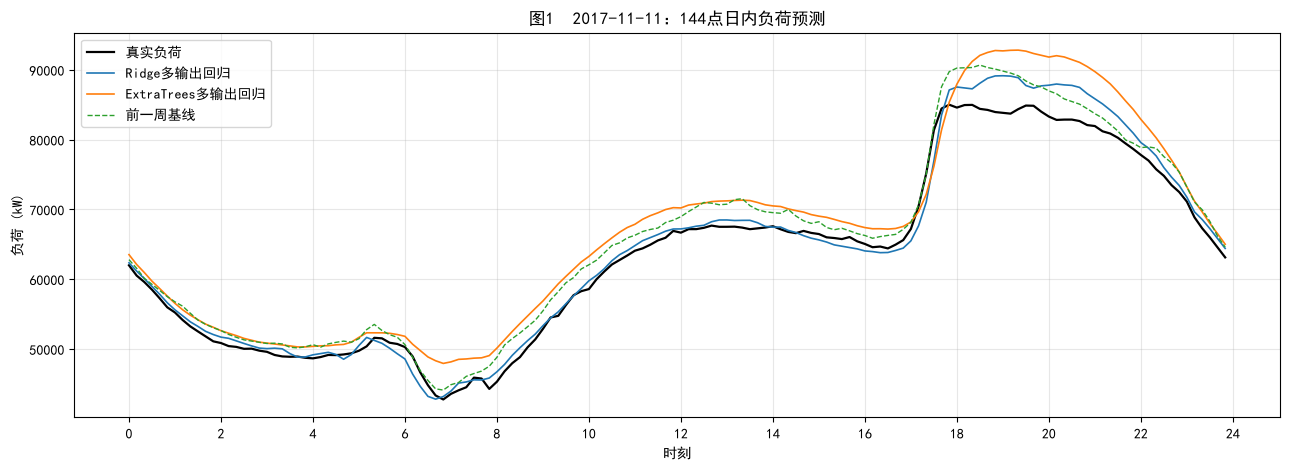

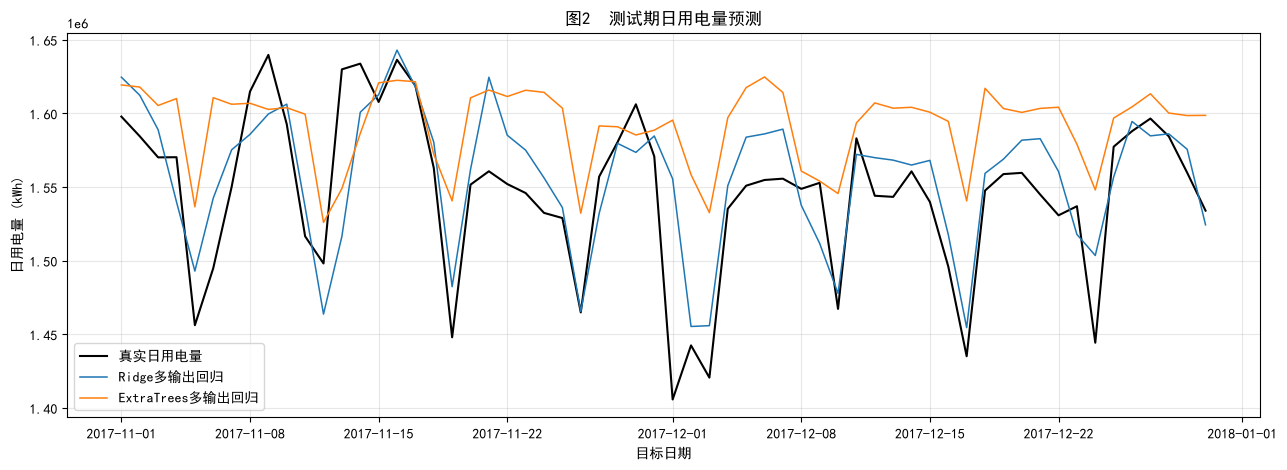

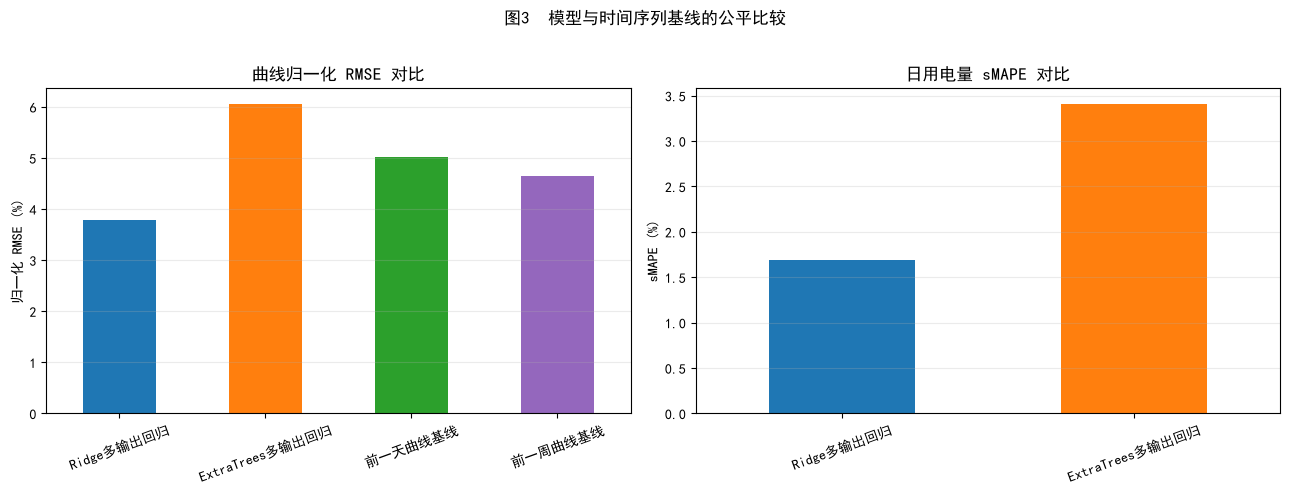

In [16]:
# 图1：测试集某一天的完整预测曲线
example_idx = min(10, len(test_dates) - 1)
slot_axis = np.arange(144) / 6
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(slot_axis, Y_test[example_idx], color='black', lw=1.6, label='真实负荷')
for name, color in [('Ridge多输出回归', '#1f77b4'), ('ExtraTrees多输出回归', '#ff7f0e')]:
    ax.plot(slot_axis, predictions[name][example_idx], color=color, lw=1.2, label=name)
ax.plot(slot_axis, day_profiles[test_dates[example_idx] - pd.Timedelta(days=7)],
        color='#2ca02c', ls='--', lw=1.0, label='前一周基线')
ax.set_title(f'图1  {test_dates[example_idx].date()}：144点日内负荷预测')
ax.set_xlabel('时刻'); ax.set_ylabel('负荷 (kW)')
ax.set_xticks(range(0, 25, 2)); ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B07_curve.png', dpi=160, bbox_inches='tight'); plt.show()

# 图2：测试期日用电量对比
fig, ax = plt.subplots(figsize=(13, 4.8))
actual_energy = Y_test.sum(axis=1) / 6
ax.plot(test_dates, actual_energy, color='black', lw=1.5, label='真实日用电量')
for name, color in [('Ridge多输出回归', '#1f77b4'), ('ExtraTrees多输出回归', '#ff7f0e')]:
    ax.plot(test_dates, predictions[name].sum(axis=1) / 6, color=color, lw=1.1, label=name)
ax.set_title('图2  测试期日用电量预测')
ax.set_xlabel('目标日期'); ax.set_ylabel('日用电量 (kWh)')
ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B07_energy.png', dpi=160, bbox_inches='tight'); plt.show()

# 图3：公平的百分比指标对比
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
all_curve_metrics.plot(x='模型', y='曲线归一化RMSE%', kind='bar', ax=axes[0],
                       color=['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd'], legend=False)
axes[0].set_title('曲线归一化 RMSE 对比'); axes[0].set_ylabel('归一化 RMSE (%)'); axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=20); axes[0].grid(alpha=0.25, axis='y')
summary_plot = summary_metrics[summary_metrics['目标'] == '日用电量(kWh)']
summary_plot.plot(x='模型', y='sMAPE%', kind='bar', ax=axes[1],
                  color=['#1f77b4', '#ff7f0e'], legend=False)
axes[1].set_title('日用电量 sMAPE 对比'); axes[1].set_ylabel('sMAPE (%)'); axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=20); axes[1].grid(alpha=0.25, axis='y')
fig.suptitle('图3  模型与时间序列基线的公平比较', y=1.02); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B07_metrics.png', dpi=160, bbox_inches='tight'); plt.show()

## 7. 结论

本版本直接预测未来一天的 144 个 10 分钟负荷点，避免了“先预测日级指标、再套固定模板”造成的曲线信息损失。

在这份数据上，最适合的输入结构是前一天曲线和前一周同日曲线：前一天反映最新状态，前一周反映相同星期结构。Ridge 多输出回归通过正则化处理两条历史曲线之间的共线性，通常比非线性树模型更适合当前“日样本较少、曲线变量高度相关”的数据条件。

评价时应同时看：

- 144 点曲线的 RMSE、MAE、sMAPE 和归一化 RMSE；
- 日用电量、日峰值和日谷值的 RMSE、sMAPE 和 R²；
- 是否超过前一天和前一周曲线基线；
- 预测曲线是否在峰谷位置和整体幅值上跟随真实曲线。

在当前数据上，直接多输出 Ridge 模型的测试曲线 RMSE 约为 2,443 kW，前一周曲线基线约为 2,987 kW，说明直接预测整条曲线比固定模板重构更适合本数据。ExtraTrees 作为非线性对照，如果误差高于 Ridge，说明当前数据量和强周期结构更适合正则化线性时间序列回归。

该结果仍然受一年数据量和缺少目标日天气预报的限制。正式调度使用时，应继续接入天气预报，并采用滚动时间验证检查不同季节的稳定性。

## 8. 对评分维度的回应

### 8.1 数据分析的全面性与深度

本项目的分析对象是全市三区总负荷 `Z_total = Z1 + Z2 + Z3`。选择总负荷而不是单独一个分区，是因为调度首先关心全市电源侧需要承担的总负荷；三区合计后还能减少局部随机波动，更接近实际调度对象。原始数据保持 10 分钟粒度，每个完整日包含 144 个观测点，因此预测结果也保持 10 分钟粒度。

数据处理中检查了时间顺序、重复时间戳、缺失值和采样间隔，只保留完整的 144 点日曲线。模型使用 2017 年 1 月至 10 月的目标日作为训练集，2017 年 11 月至 12 月作为严格按时间顺序的测试集，共评价 60 个未来日。输入选择前一天和前一周的完整负荷曲线，是因为该数据同时具有短期惯性、日周期和周周期：前一天反映最近状态，前一周对应相同星期结构。目标日的真实负荷和真实天气没有进入输入。

### 8.2 方法选择、运用与评估质量

本项目比较了两种具有不同假设的多输出回归模型：

- **Ridge 多输出回归**：适合历史曲线变量高度相关、日级样本相对较少的情况，L2 正则化可以降低共线性和过拟合影响；
- **ExtraTrees 多输出回归**：用于检验非线性划分和变量交互是否能够带来额外收益，并通过限制树深、叶节点样本数和特征比例控制复杂度。

两种模型使用完全相同的输入、训练集、测试集和 144 点输出目标，保证比较公平。同时保留前一天曲线和前一周曲线作为业务上有意义的强基线。评价不只看一个指标，而是同时使用 MSE、RMSE、MAE、sMAPE、归一化 RMSE 和 R²；其中百分比指标用于不同量纲之间的公平比较，曲线指标用于判断模型是否真正适合调度。

测试结果显示，Ridge 多输出回归的曲线 RMSE 约为 2,443 kW，曲线 sMAPE 约为 2.65%，曲线 R²约为 0.326；ExtraTrees 的曲线 RMSE 约为 3,902 kW，曲线 sMAPE 约为 4.73%，R²为负。Ridge 还将日用电量预测的 sMAPE 降到约 1.69%，说明在这份数据上，正则化线性结构比复杂树模型更适合。

### 8.3 数据可视化的有效性

- **图 1**：展示一个测试日的 144 点真实负荷、Ridge 预测、ExtraTrees 预测和前一周基线，直接观察峰谷跟踪、幅值偏差和局部波动；
- **图 2**：展示整个测试期的日用电量真实值与两种模型预测值，观察模型是否存在连续高估、低估或季节漂移；
- **图 3**：比较模型与基线的归一化 RMSE 和日用电量 sMAPE，把模型优劣转换为直观的百分比指标。

这些图分别回答“单日曲线是否贴合”“整个测试期是否稳定”和“模型是否超过简单基线”三个问题，和表格指标形成互相验证。

### 8.4 结论论证、独立思考与创新性

结论不是依据复杂模型名称或单次最好结果得出，而是依据同一测试集上的多指标和基线比较得出：Ridge 多输出回归在完整曲线、日用电量、峰值和谷值指标上整体优于 ExtraTrees，也优于前一天曲线基线；前一周曲线基线仍然很强，但 Ridge 已将曲线 RMSE 从约 2,987 kW 降至约 2,443 kW，说明历史曲线之间确实存在可学习的额外关系。

本项目的独立思考体现在两个方面：第一，发现“先预测日级摘要、再套固定星期模板”会损失日内变化，因此改为直接预测未来 144 点；第二，没有把更复杂的 ExtraTrees 默认当作更好的模型，而是根据样本规模、曲线共线性和测试结果选择正则化 Ridge。直接多输出、双季节曲线输入、强基线比较和百分比指标评价共同构成了本项目的改进点。

同时，结论明确保留适用边界：当前数据只有一年，目标日天气预报尚未接入，模型适合课程项目中的日 ahead 负荷预测和方法比较；正式调度还应加入天气预报、多年份滚动验证和预测区间。